In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Read in the Excel files
all_weeks_countries_netflix = pd.read_excel('all-weeks-countries-netflix.xlsx')
all_weeks_global_netflix = pd.read_excel('all-weeks-global-netflix.xlsx')
most_popular_netflix = pd.read_excel('most-popular-netflix.xlsx')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no de

In [33]:
all_weeks_countries_netflix.sample(30).to_csv('all_weeks_countries_netflix_sample.csv', index=False)
all_weeks_global_netflix.sample(30).to_csv('all_weeks_global_netflix_sample.csv', index=False)
most_popular_netflix.sample(30).to_csv('most_popular_netflix_sample.csv', index=False)

In [34]:

print(all_weeks_global_netflix['category'].unique())


['Films (English)' 'Films (Non-English)' 'TV (English)' 'TV (Non-English)']


In [35]:
category_sums = all_weeks_global_netflix.groupby('category')['weekly_hours_viewed'].sum()
print(category_sums)

category
Films (English)        22069420000
Films (Non-English)     9680460000
TV (English)           46591630000
TV (Non-English)       29740210000
Name: weekly_hours_viewed, dtype: int64


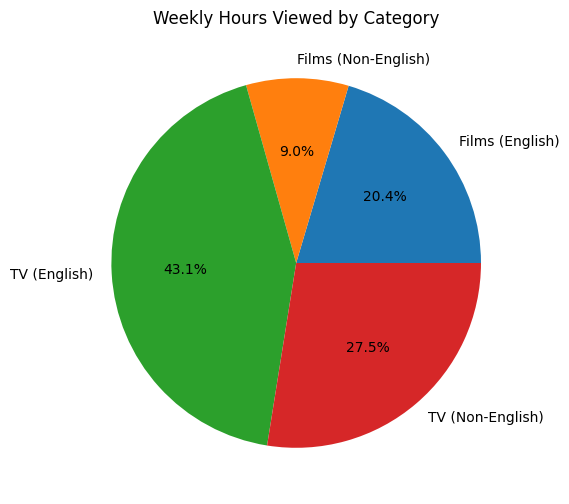

In [36]:
import matplotlib.pyplot as plt

category_sums.plot.pie(autopct='%1.1f%%', figsize=(6, 6), ylabel='', title='Weekly Hours Viewed by Category')
plt.show()

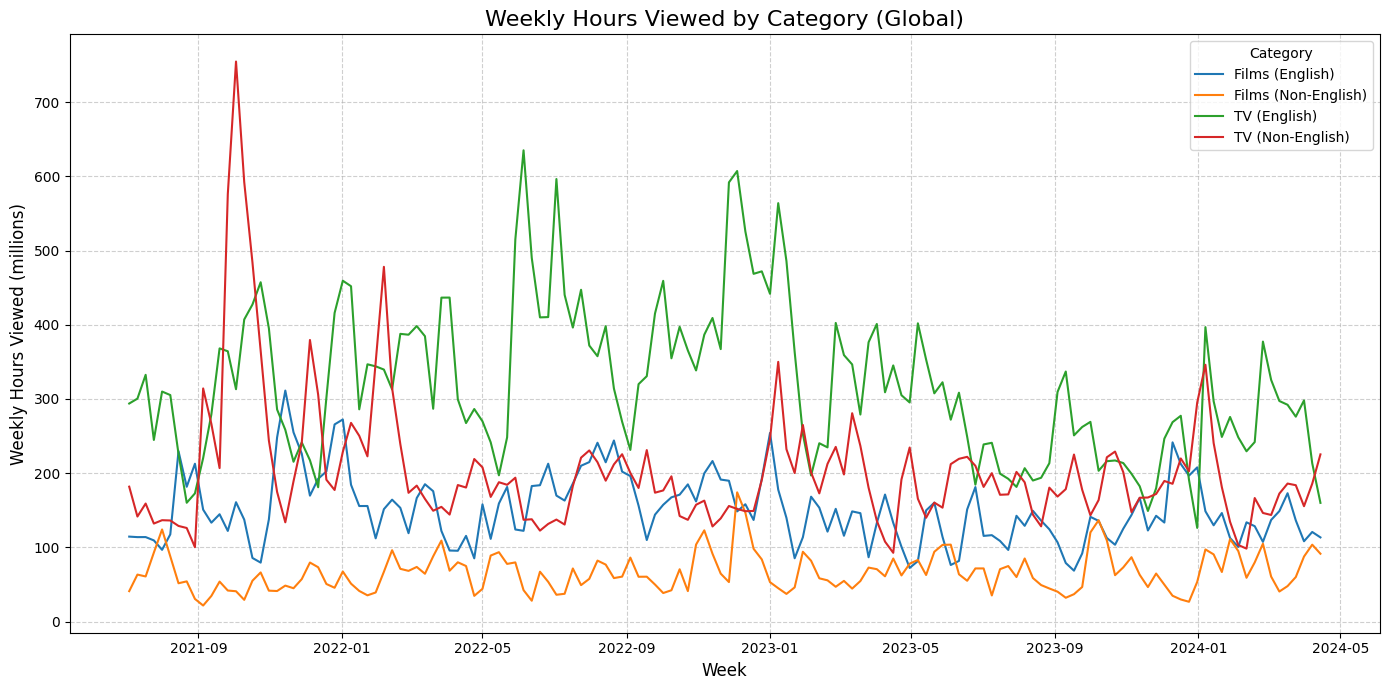

In [37]:
# Convert week to datetime
all_weeks_global_netflix["week"] = pd.to_datetime(all_weeks_global_netflix["week"], errors="coerce")

# Group by week and category, summing hours viewed
weekly_trends = (
    all_weeks_global_netflix.groupby(["week", "category"])["weekly_hours_viewed"]
    .sum()
    .reset_index()
)

# Pivot for plotting
pivot_trends = weekly_trends.pivot(index="week", columns="category", values="weekly_hours_viewed")

# Convert to millions for better readability
pivot_trends_millions = pivot_trends / 1e6

plt.figure(figsize=(14, 7))
for col in pivot_trends_millions.columns:
    plt.plot(pivot_trends_millions.index, pivot_trends_millions[col], label=col)

plt.title("Weekly Hours Viewed by Category (Global)", fontsize=16)
plt.xlabel("Week", fontsize=12)
plt.ylabel("Weekly Hours Viewed (millions)", fontsize=12)
plt.legend(title="Category")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


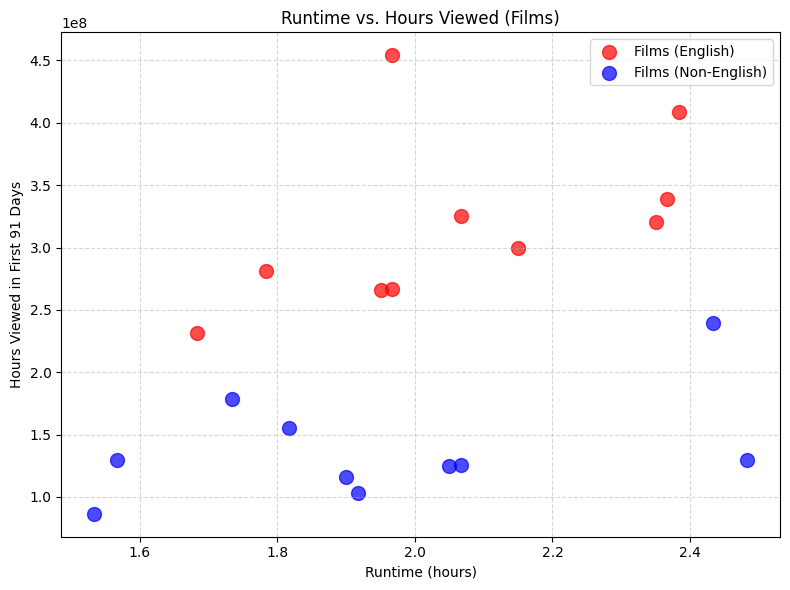

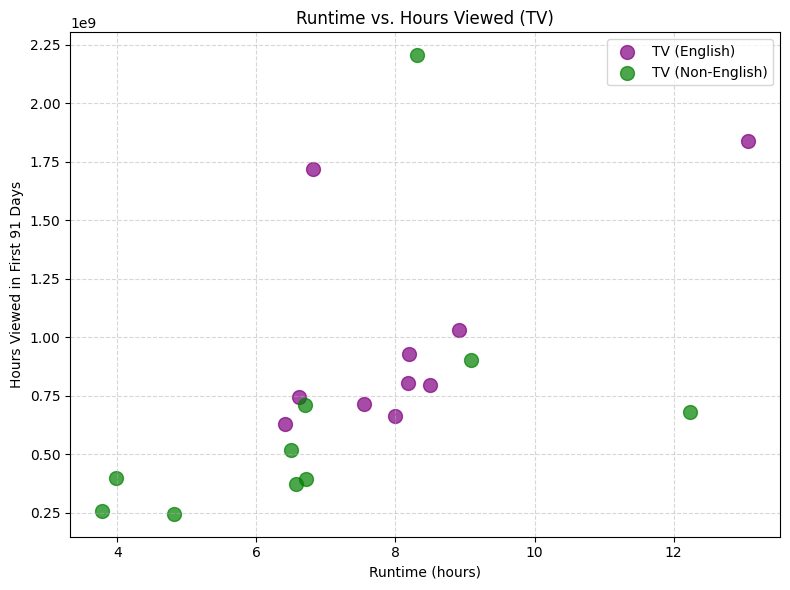

In [38]:

# Scatter plot for Films (English) and Films (Non-English)
films_df = most_popular_netflix[most_popular_netflix['category'].isin(['Films (English)', 'Films (Non-English)'])]

plt.figure(figsize=(8, 6))
for cat, color in zip(['Films (English)', 'Films (Non-English)'], ['red', 'blue']):
    subset = films_df[films_df['category'] == cat]
    plt.scatter(subset['runtime'], subset['hours_viewed_first_91_days'], alpha=0.7, label=cat, color=color, s=100)
plt.xlabel('Runtime (hours)')
plt.ylabel('Hours Viewed in First 91 Days')
plt.title('Runtime vs. Hours Viewed (Films)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Scatter plot for TV (English) and TV (Non-English)
tv_df = most_popular_netflix[most_popular_netflix['category'].isin(['TV (English)', 'TV (Non-English)'])]

plt.figure(figsize=(8, 6))
for cat, color in zip(['TV (English)', 'TV (Non-English)'], ['purple', 'green']):
    subset = tv_df[tv_df['category'] == cat]
    plt.scatter(subset['runtime'], subset['hours_viewed_first_91_days'], alpha=0.7, label=cat, color=color, s=100)
plt.xlabel('Runtime (hours)')
plt.ylabel('Hours Viewed in First 91 Days')
plt.title('Runtime vs. Hours Viewed (TV)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

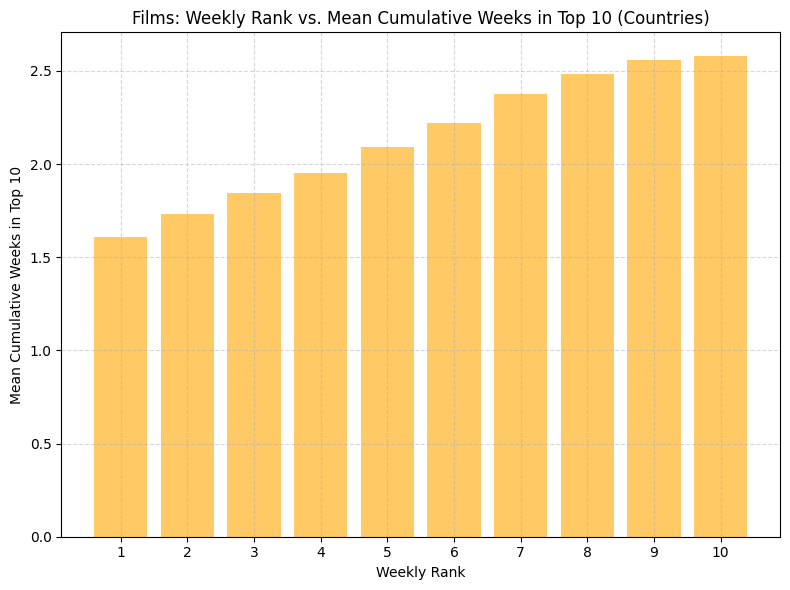

In [39]:
# Filter for category == 'Films'
films_countries_df = all_weeks_countries_netflix[all_weeks_countries_netflix['category'] == 'Films']

# Group by weekly_rank and calculate mean cumulative_weeks_in_top_10
rank_means = films_countries_df.groupby('weekly_rank')['cumulative_weeks_in_top_10'].mean().reset_index()

plt.figure(figsize=(8, 6))
plt.bar(rank_means['weekly_rank'], rank_means['cumulative_weeks_in_top_10'], color='orange', alpha=0.6)
plt.xlabel('Weekly Rank')
plt.ylabel('Mean Cumulative Weeks in Top 10')
plt.title('Films: Weekly Rank vs. Mean Cumulative Weeks in Top 10 (Countries)')
plt.xticks(range(1, 11))  # Ensure x-ticks from 1 to 10
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()